In [8]:
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

# Reading image

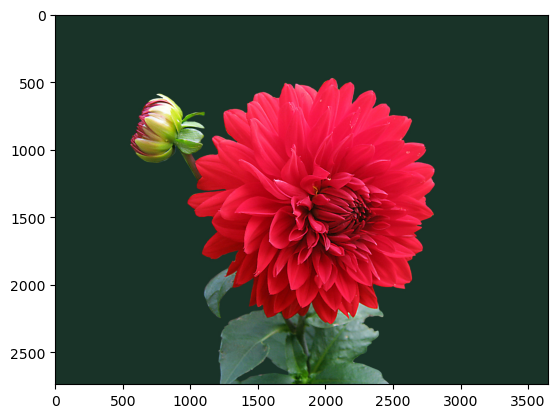

In [9]:
Raw_image = mpimg.imread("pic5.jpeg")
image_matrix = Raw_image.astype(np.float64)
m, n, k = image_matrix.shape
plt.imshow(Raw_image)

# Adding noise

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


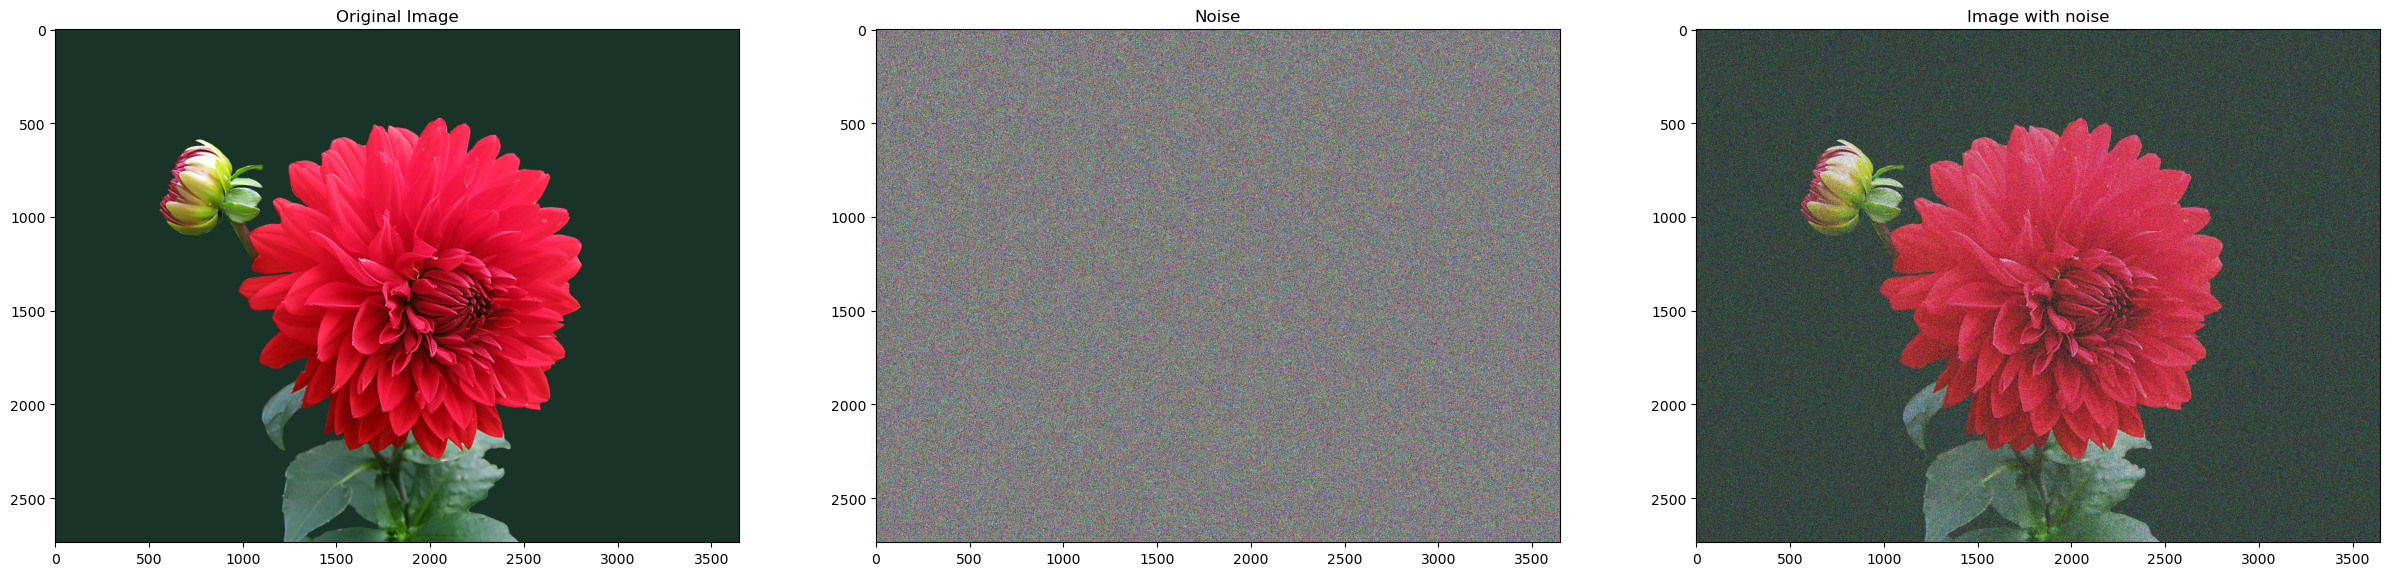

In [10]:
mu, sigma= 0, 100
gaussian_noise = np.random.normal(mu, sigma, (m, n, k))

image_with_noise = (image_matrix + gaussian_noise) / 255

fig, ax = plt.subplots(1, 3, figsize=(30, 30))
ax[0].imshow(Raw_image)
ax[0].set_title("Original Image")
ax[1].imshow(gaussian_noise)
ax[1].set_title("Noise")
ax[2].imshow(image_with_noise)
ax[2].set_title("Image with noise")

plt.savefig("Images Combined.png", dpi=900)

# SVD decomposition of each channel

In [11]:
R_1 = image_with_noise[:, :, 0]
G_1 = image_with_noise[:, :, 1]
B_1 = image_with_noise[:, :, 2]

U_R, s_R, V_R = np.linalg.svd(R_1)
U_G, s_G, V_G = np.linalg.svd(G_1)
U_B, s_B, V_B = np.linalg.svd(B_1)

S_R = np.diag(s_R)
S_G = np.diag(s_G)
S_B = np.diag(s_B)

# Plotting with different K

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

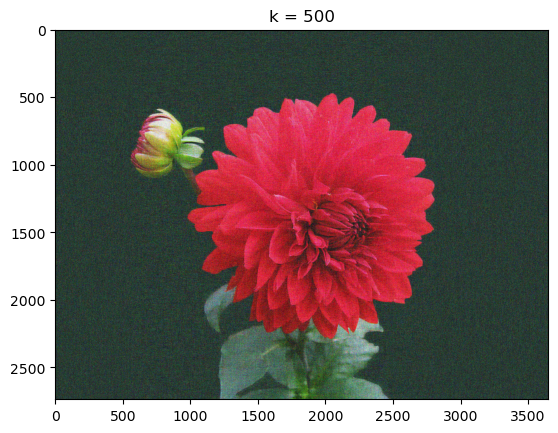

In [12]:
for r in range(50, 501, 50):

    reconstructed_R = np.dot(np.dot(U_R[:,:r], S_R[:r,:r]), V_R[:r,:])
    reconstructed_G = np.dot(np.dot(U_G[:,:r], S_G[:r,:r]), V_G[:r,:])
    reconstructed_B = np.dot(np.dot(U_B[:,:r], S_B[:r,:r]), V_B[:r,:])

    image = np.empty([m, n, k])

    image[:, :, 0] = reconstructed_R
    image[:, :, 1] = reconstructed_G
    image[:, :, 2] = reconstructed_B

    plt.imshow(image)
    plt.title(f"k = {r}")
    plt.savefig(f"K = {r}.jpg", dpi=600)


# Plotting the Singular Values

Text(0.5, 1.0, 'Singular Values for Blue channel')

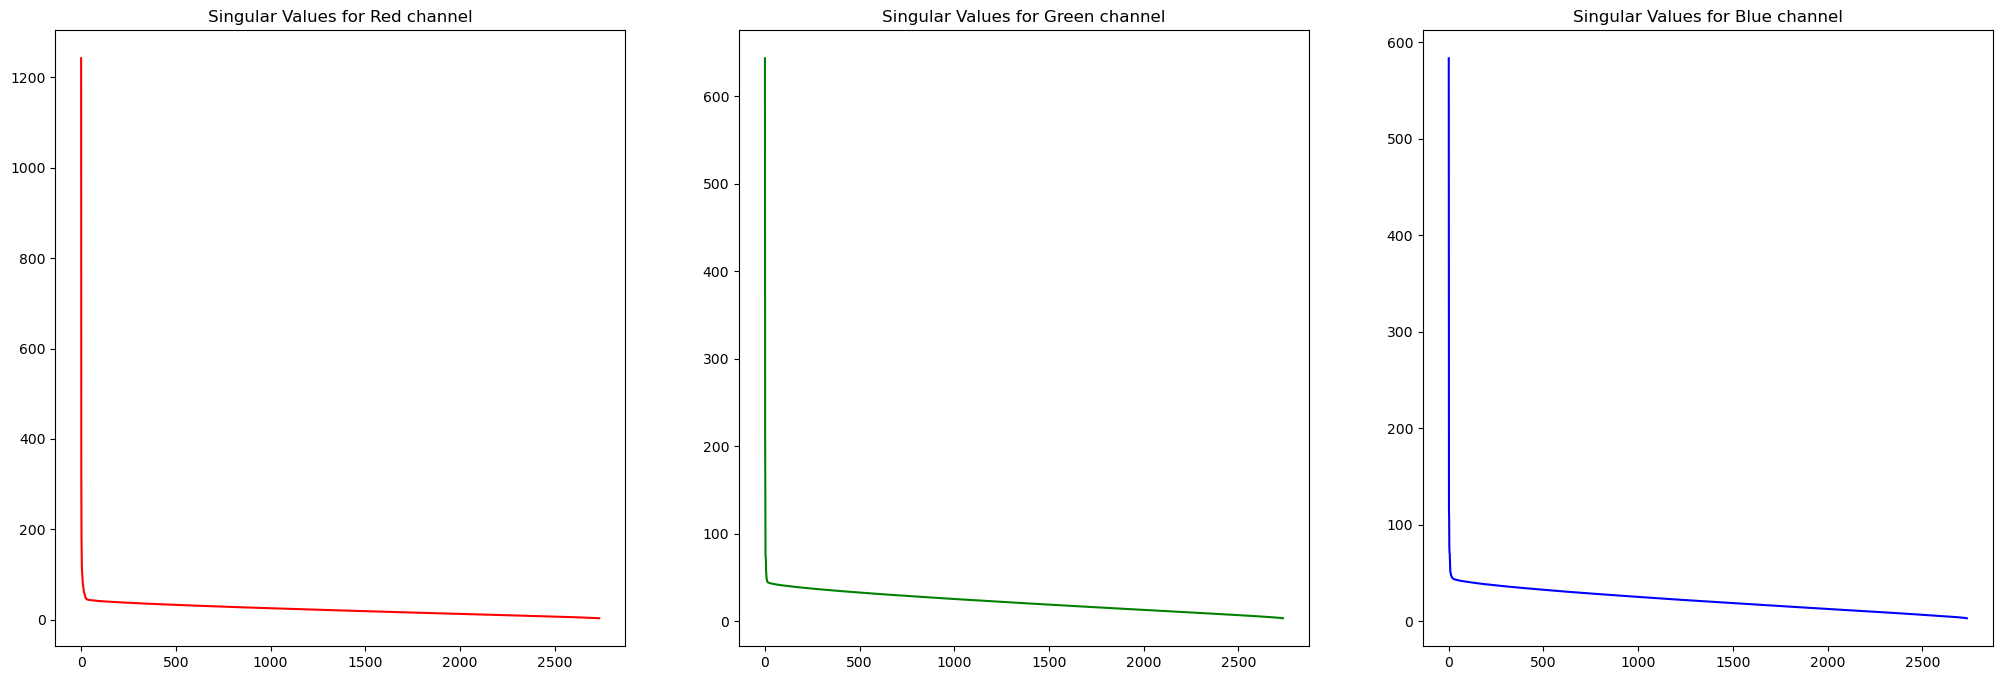

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(25, 8))

ax[0].plot(np.arange(0, s_R.shape[0]), s_R, c="red")
ax[0].set_title("Singular Values for Red channel")

ax[1].plot(np.arange(0, s_G.shape[0]), s_G, c="green")
ax[1].set_title("Singular Values for Green channel")

ax[2].plot(np.arange(0, s_B.shape[0]), s_B, c="blue")
ax[2].set_title("Singular Values for Blue channel")

# Selecting best K